In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.basemap import Basemap

plt.style.use('dark_background') # Включаем тёмную тему
plt.rcParams.update({
    'figure.facecolor': '#121212',    # Цвет фона холста
    'axes.facecolor': '#1e1e1e',      # Цвет фона области графика
    'axes.edgecolor': '#444444',      # Цвет рамок
    'axes.labelcolor': '#e0e0e0',     # Цвет подписей осей
    'xtick.color': '#e0e0e0',         # Цвет делений осей
    'ytick.color': '#e0e0e0',
    'grid.color': '#333333',          # Цвет сетки
    'grid.linestyle': '--',
    'font.family': 'sans-serif',
    'font.size': 12,
    'axes.titlesize': 16,
    'axes.titleweight': 'bold',
    'axes.titlepad': 20,
    'figure.figsize': (12, 7),
    'figure.dpi': 120                 # Высокое разрешение 
})


cols_to_str = ['SCHEDULED_DEPARTURE', 'DEPARTURE_TIME', 'SCHEDULED_ARRIVAL', 'ARRIVAL_TIME']
df = pd.read_csv('flights/flights.csv', dtype={col: str for col in cols_to_str}, low_memory=False)
df = df.dropna(subset=['DEPARTURE_TIME', 'ARRIVAL_TIME'])
delay_cols = ['DEPARTURE_DELAY', 'ARRIVAL_DELAY', 'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 
              'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']
for col in delay_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
print(f"Размер очищенного датасета: {df.shape}")

Размер очищенного датасета: (5726566, 31)


1) Для начала посмотрим насколько в среднем разные авиакомпании задерживают рейсы

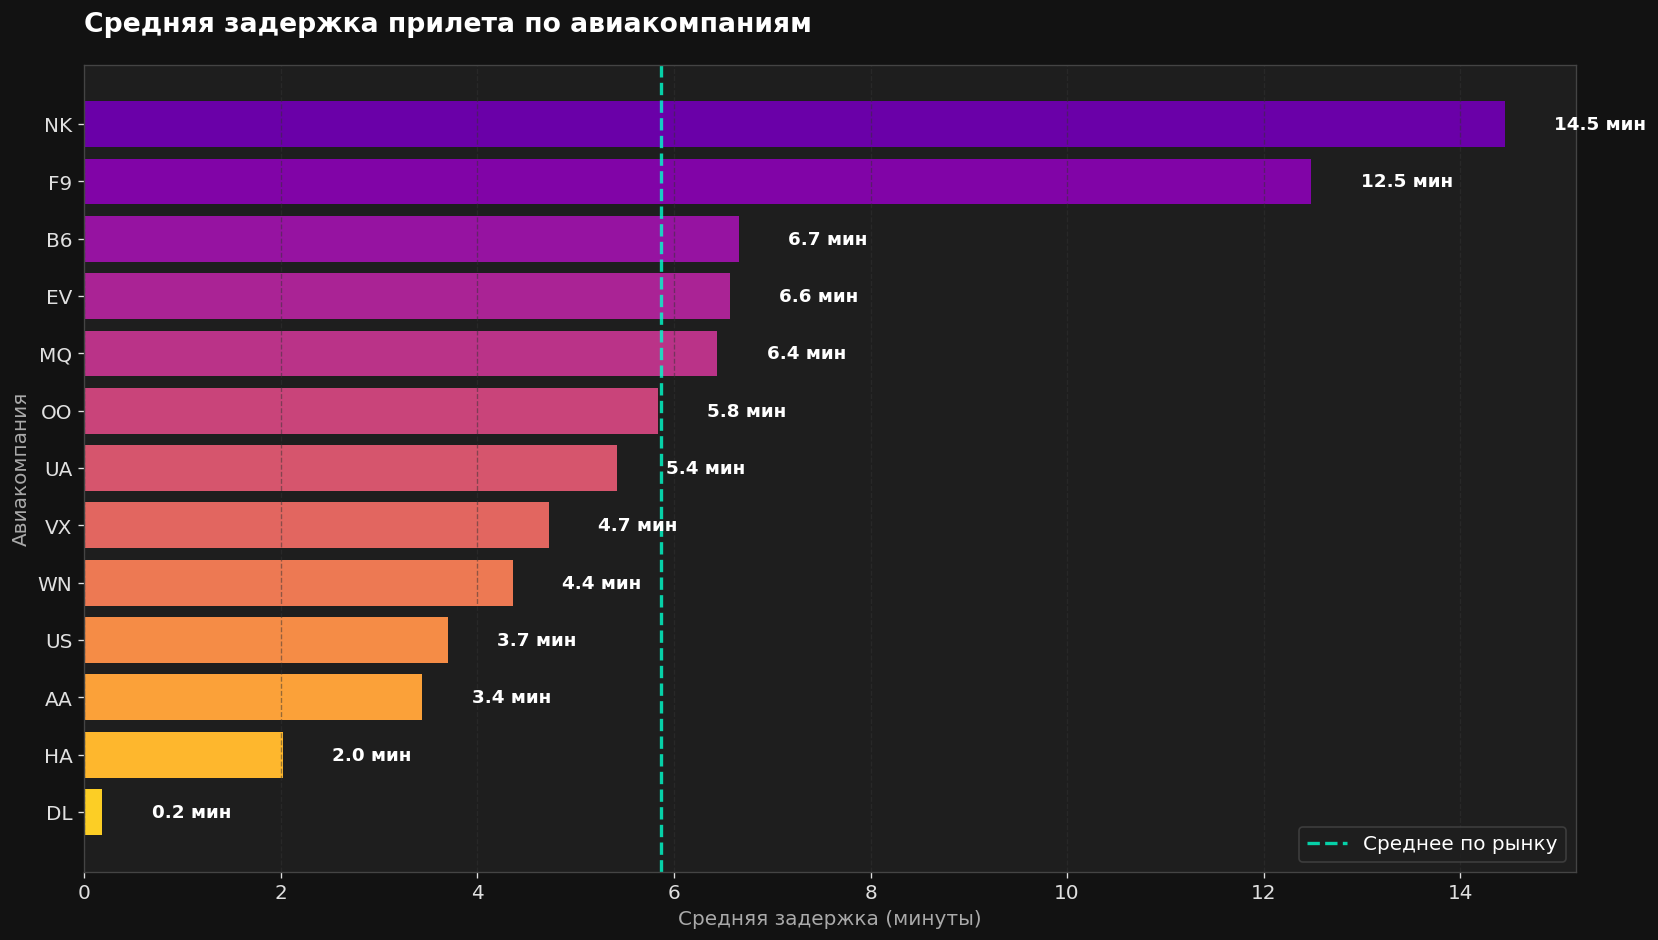

In [27]:
airline_stats = df.groupby('AIRLINE')['ARRIVAL_DELAY'].mean().sort_values(ascending=False)
airline_stats = airline_stats[airline_stats > 0]

plt.figure(figsize=(14, 8))
#Граиент
colors = plt.cm.plasma(np.linspace(0.2, 0.9, len(airline_stats)))

# Строим горизонтальные бары (barh), убираем обводку (edgecolor='none')
bars = plt.barh(airline_stats.index, airline_stats.values, color=colors, edgecolor='none')

#Среднее
mean_val = airline_stats.mean()
plt.axvline(x=mean_val, color='#00ffcc', linestyle='--', linewidth=2, alpha=0.8, label='Среднее по рынку')

#Значения на столбиках
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.5, bar.get_y() + bar.get_height()/2, 
             f'{width:.1f} мин', va='center', ha='left', color='#ffffff', fontsize=11, fontweight='bold')

plt.title('Средняя задержка прилета по авиакомпаниям', loc='left', color='#ffffff')
plt.xlabel('Средняя задержка (минуты)', color='#aaaaaa')
plt.ylabel('Авиакомпания', color='#aaaaaa')
plt.legend(loc='lower right', facecolor='#1e1e1e', edgecolor='#444444')
plt.grid(axis='x', alpha=0.5)
plt.gca().invert_yaxis() # Переворачиваем, чтобы самая большая задержка была сверху
plt.tight_layout()
plt.show()

Анализ показывает, что компании существенно различаются по средней задержке рейсов.

2) Теперь посмотрим, в какие дни и месяцы аэропорты хуже всего справляются с нагрузкой

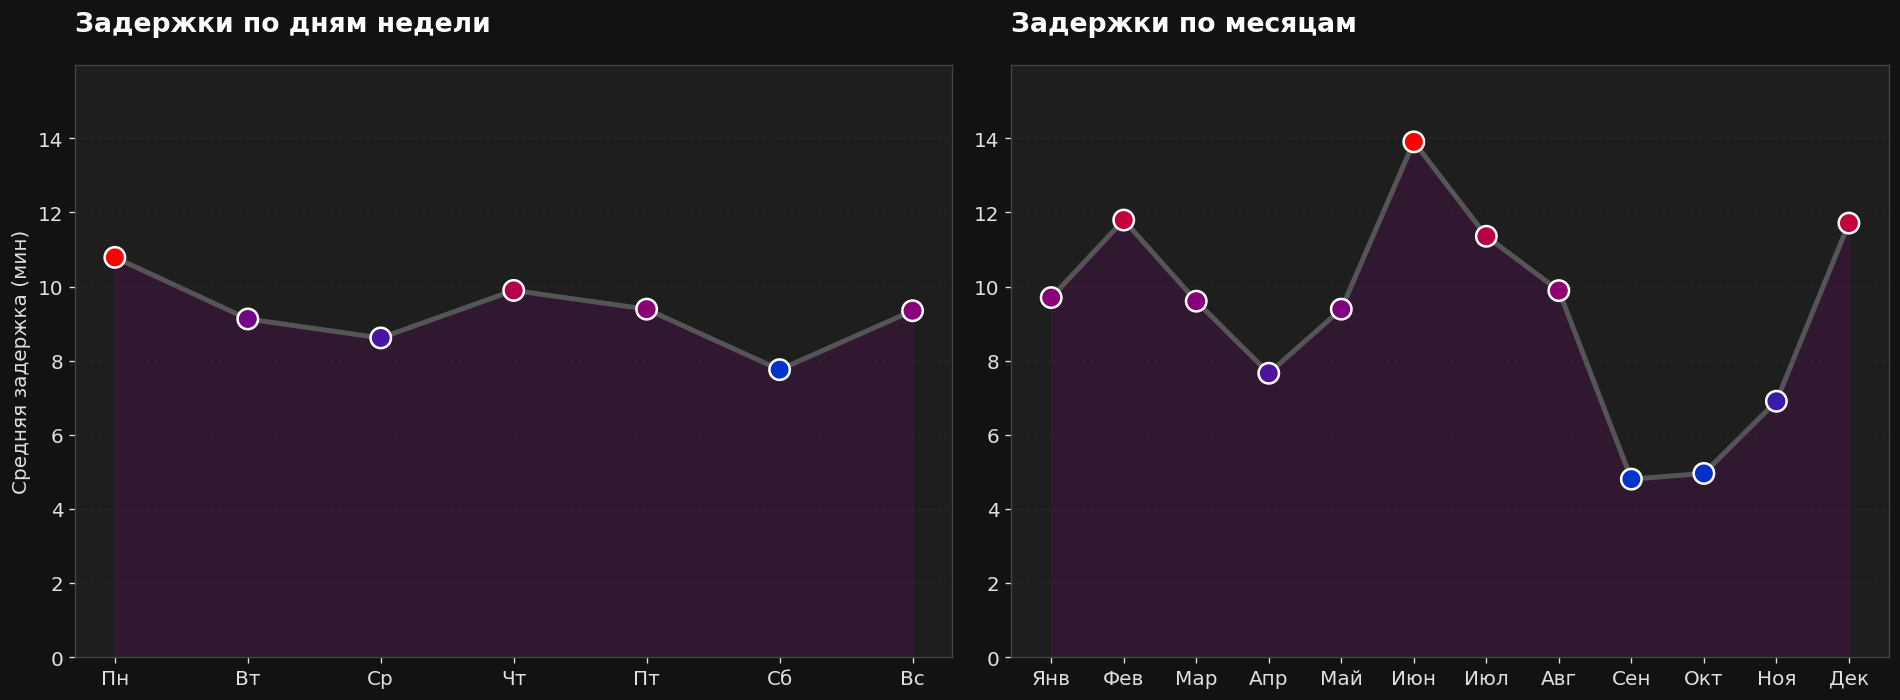

In [29]:
day_delay = df.groupby('DAY_OF_WEEK')['DEPARTURE_DELAY'].mean()
month_delay = df.groupby('MONTH')['DEPARTURE_DELAY'].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))


global_max = max(day_delay.max(), month_delay.max())
#Добавляем место сверху максимума 
y_limit = global_max * 1.15 

#Дни недели
axes[0].plot(day_delay.index, day_delay.values, color='#555555', linewidth=3, zorder=1)
sc0 = axes[0].scatter(day_delay.index, day_delay.values, c=day_delay.values, cmap=custom_cmap, 
                      s=150, zorder=2, edgecolors='#ffffff', linewidth=1.5)
axes[0].fill_between(day_delay.index, day_delay.values, color='#800080', alpha=0.2, zorder=0)

axes[0].set_title('Задержки по дням недели', loc='left')
axes[0].set_xticks(range(1, 8))
axes[0].set_xticklabels(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
axes[0].set_ylabel('Средняя задержка (мин)')
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim(0, y_limit) # ПРИМЕНЯЕМ ОДИНАКОВЫЙ ЛИМИТ

#Месяцы
axes[1].plot(month_delay.index, month_delay.values, color='#555555', linewidth=3, zorder=1)
sc1 = axes[1].scatter(month_delay.index, month_delay.values, c=month_delay.values, cmap=custom_cmap, 
                      s=150, zorder=2, edgecolors='#ffffff', linewidth=1.5)
axes[1].fill_between(month_delay.index, month_delay.values, color='#800080', alpha=0.2, zorder=0)

axes[1].set_title('Задержки по месяцам', loc='left')
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек'])
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim(0, y_limit) 

plt.tight_layout()
plt.show()

Анализ показывает, что пик задержек стабильно приходится на конец рабочей недели (четверг и пятницу) и на сезонные пики (июнь-июль, декабрь). Это может быть связано, с тем, что большинство людей именно в эти дни и месяцы летят на выходные или в отпуск

3) Посмотрим по каким причинам чаще всего происходят задержки 

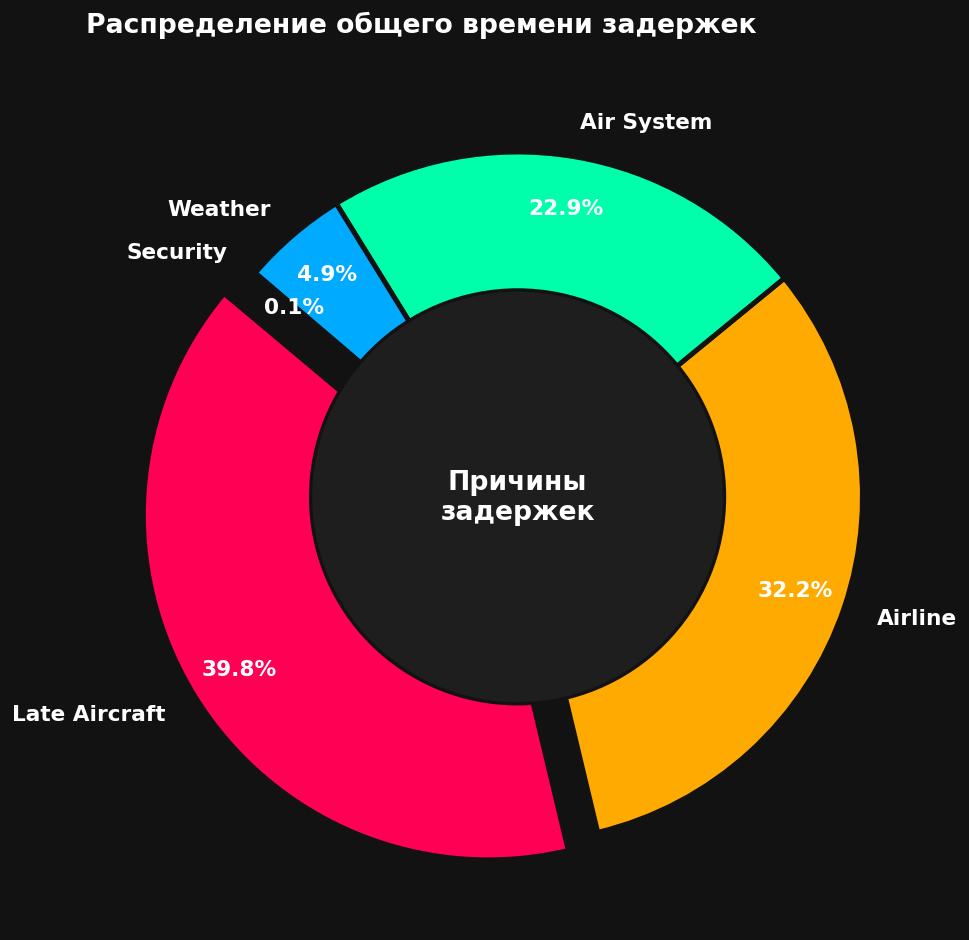

In [32]:
causes = {
    'Late Aircraft': df['LATE_AIRCRAFT_DELAY'].sum(),
    'Airline': df['AIRLINE_DELAY'].sum(),
    'Air System': df['AIR_SYSTEM_DELAY'].sum(),
    'Weather': df['WEATHER_DELAY'].sum(),
    'Security': df['SECURITY_DELAY'].sum()
}
causes_series = pd.Series(causes).sort_values(ascending=False)

colors = ['#ff0055', '#ffaa00', '#00ffaa', '#00aaff', '#aa00ff']
explode = (0.1, 0, 0, 0, 0) #Выдвигаем самый большой сектор

plt.figure(figsize=(10, 8))
wedges, texts, autotexts = plt.pie(
    causes_series, 
    labels=causes_series.index, 
    autopct='%1.1f%%', 
    startangle=140,
    colors=colors, 
    explode=explode,
    pctdistance=0.85, # Отодвигаем проценты к краю
    textprops={'color': '#ffffff', 'fontsize': 13, 'fontweight': 'bold'},
    wedgeprops={'edgecolor': '#121212', 'linewidth': 3} # Темная обводка
)

#Круг в центре
centre_circle = plt.Circle((0,0), 0.60, fc='#1e1e1e', edgecolor='#121212', linewidth=2)
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

#Текст в центре
plt.text(0, 0, 'Причины\nзадержек', ha='center', va='center', fontsize=16, fontweight='bold', color='#ffffff')

plt.title('Распределение общего времени задержек', loc='left', pad=20)
plt.tight_layout()
plt.show()

Большая часть задержек — это "Late Aircraft"  и "Airline Delay" (вина компании).
Возможная причина: жёсткое расписание без резервов. Самолет летает по 4-6 раз в день, и опоздание утром передается всем последующим рейсам.

4) Посмотрим, могут ли пилоты компенсировать задержку вылета в воздухе, или опоздание на выходе гарантированно приводит к опозданию на посадку.

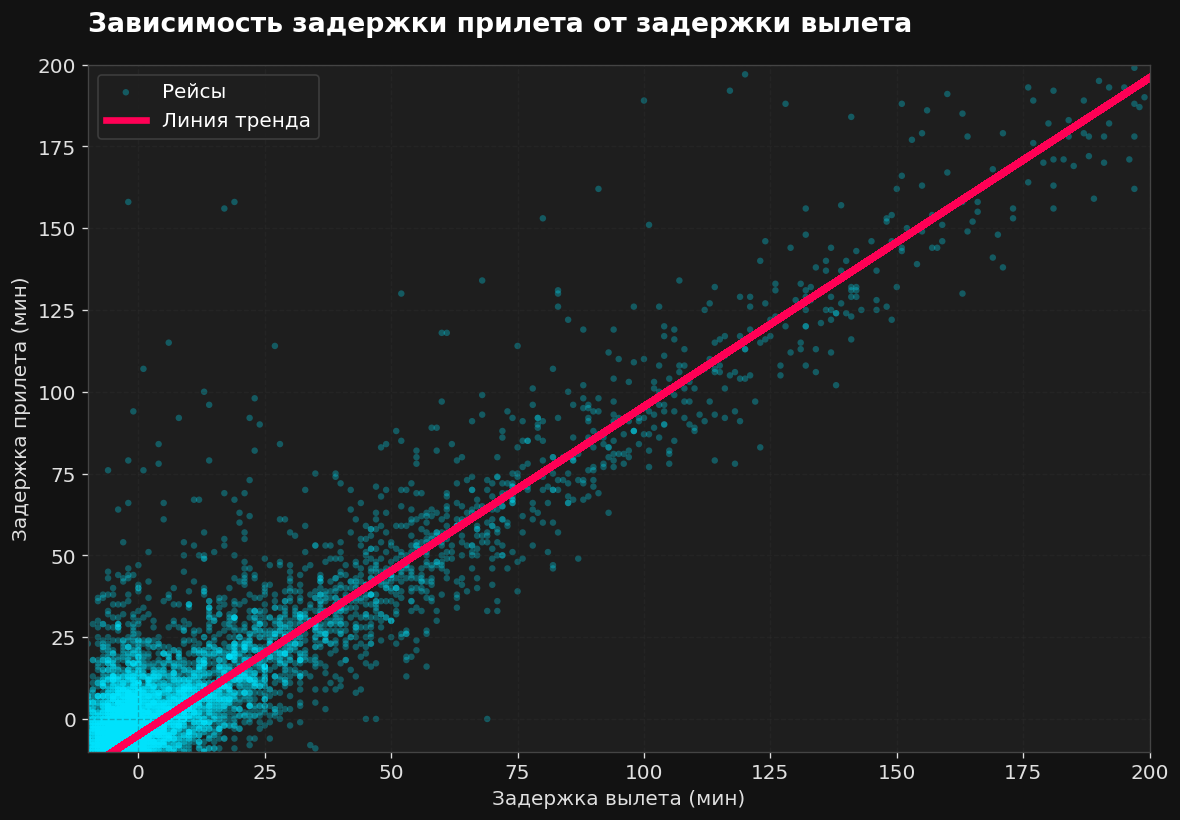

In [34]:
sample_df = df.sample(n=10000, random_state=42)
x = sample_df['DEPARTURE_DELAY']
y = sample_df['ARRIVAL_DELAY']

plt.figure(figsize=(10, 7))

plt.scatter(x, y, s=15, alpha=0.3, c='#00e5ff', edgecolors='none', label='Рейсы')

#Линия тренда
z = np.polyfit(x, y, 1)
p = np.poly1d(z)
plt.plot(x, p(x), color='#ff0055', linewidth=4, label='Линия тренда')

plt.title('Зависимость задержки прилета от задержки вылета', loc='left')
plt.xlabel('Задержка вылета (мин)')
plt.ylabel('Задержка прилета (мин)')
plt.xlim(-10, 200)
plt.ylim(-10, 200)


plt.legend(loc='upper left', facecolor='#1e1e1e', edgecolor='#444444', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Анализ показывает, что наблюдается  линейная зависимость. Задержка вылета почти на 100% переходит в задержку прилета. Возиожно, это происходит из-за экономии топлива в связи с которой самолеты должны лететь с определенной скоростью и ограничений диспетчеров 

5)  Наносим среднюю задержку на карту США, чтобы выявить географические «горячие точки» — аэропорты или регионы, где система работает хуже всего.

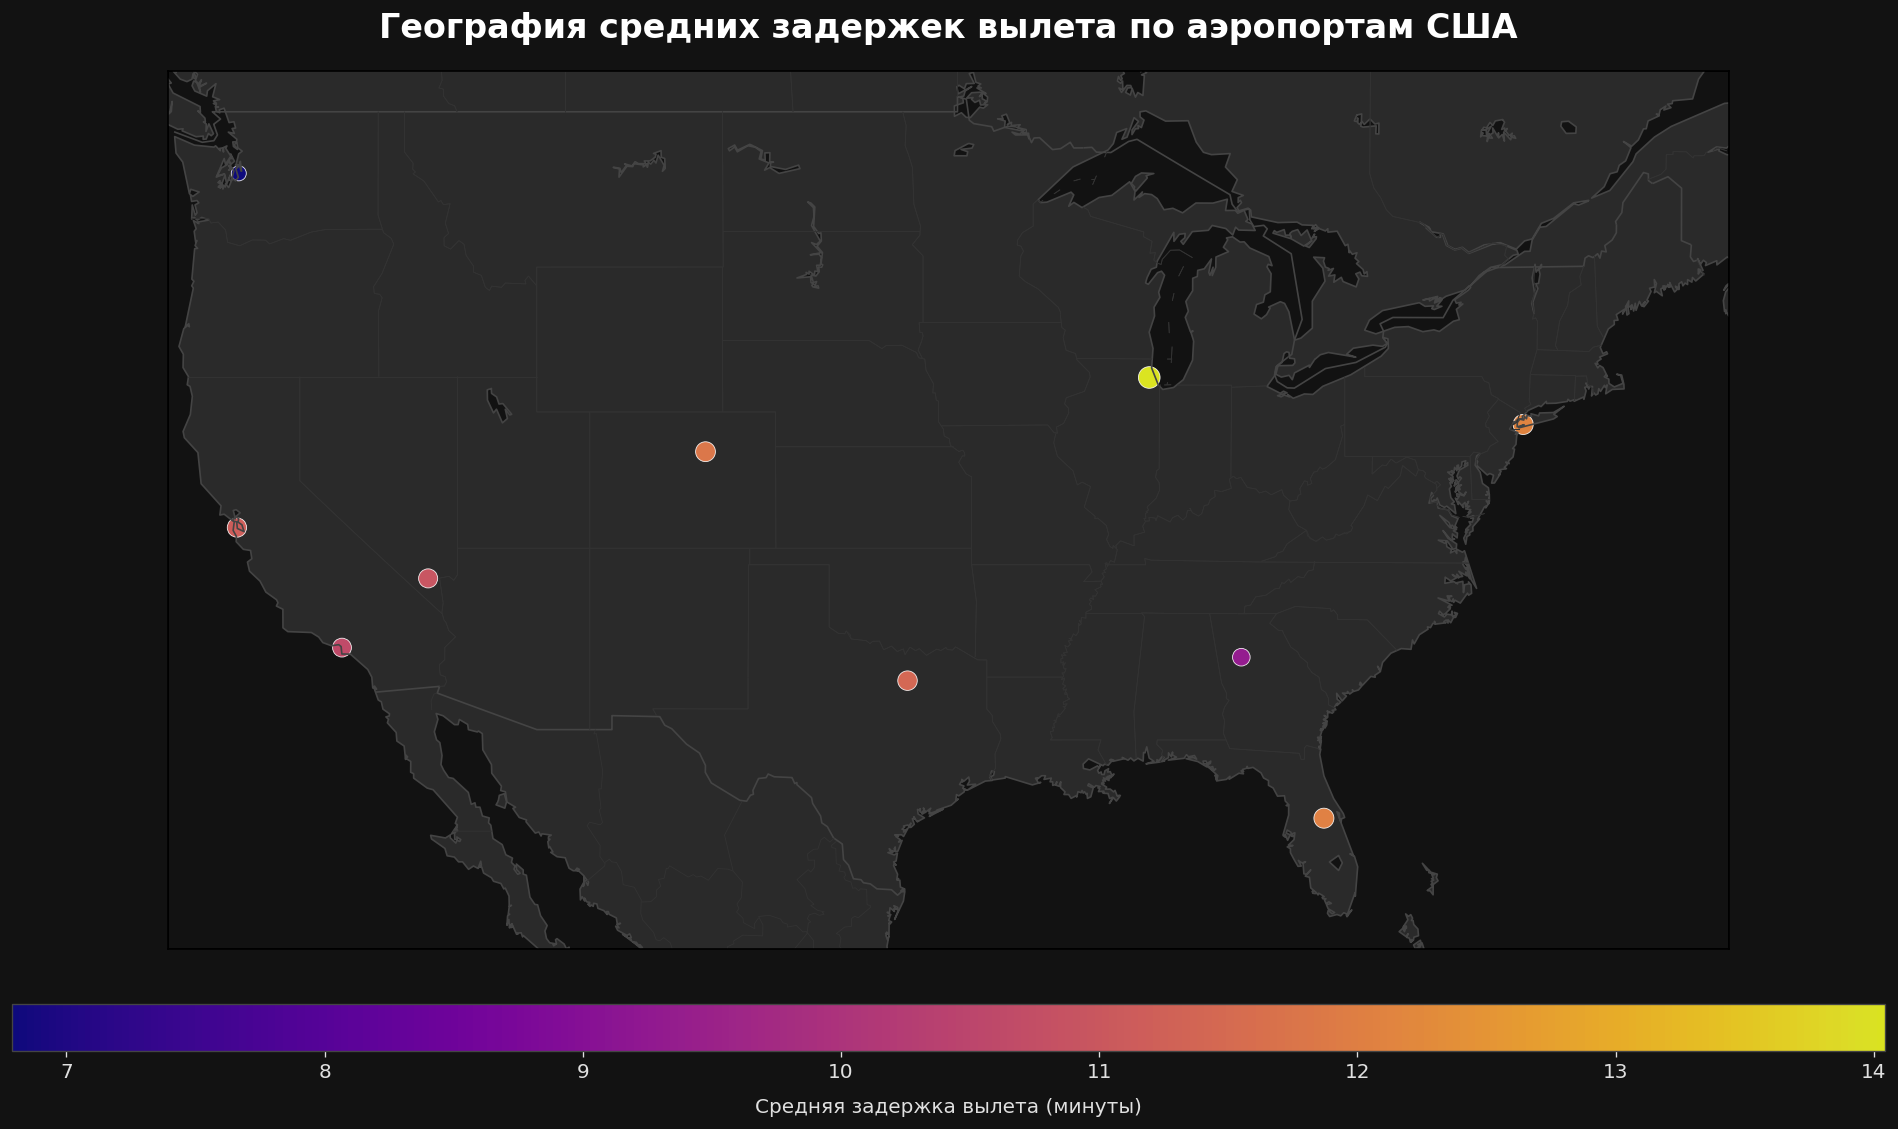

In [ ]:
airport_delays = df.groupby('ORIGIN_AIRPORT')['DEPARTURE_DELAY'].mean().reset_index()
airport_delays.columns = ['IATA_CODE', 'AVG_DELAY']
airport_delays = airport_delays[(airport_delays['AVG_DELAY'] > 0) & (airport_delays['AVG_DELAY'] < 60)]
map_data = pd.merge(airport_delays, airports, on='IATA_CODE', how='inner')

plt.figure(figsize=(16, 10))
#Тёмная карта
m = Basemap(projection='merc', llcrnrlon=-125, llcrnrlat=24, urcrnrlon=-66, urcrnrlat=50, 
            lat_ts=20, resolution='l')

#Заливка океана
m.drawmapboundary(fill_color='#121212') 
m.fillcontinents(color='#2a2a2a', lake_color='#121212')
m.drawcoastlines(linewidth=1, color='#444444')
m.drawcountries(linewidth=1, color='#444444')
m.drawstates(linewidth=0.5, color='#333333')

x, y = m(map_data['LONGITUDE'].values, map_data['LATITUDE'].values)
scatter = m.scatter(x, y, s=map_data['AVG_DELAY']*12, c=map_data['AVG_DELAY'], 
                    cmap='plasma', alpha=0.9, edgecolors='white', linewidths=0.5)

cbar = plt.colorbar(scatter, orientation='horizontal', pad=0.05, aspect=40)
cbar.set_label('Средняя задержка вылета (минуты)', color='#e0e0e0', fontsize=12, labelpad=10)
cbar.ax.xaxis.set_tick_params(color='#e0e0e0')
plt.setp(plt.getp(cbar.ax.axes, 'xticklabels'), color='#e0e0e0')

plt.title('География средних задержек вылета по аэропортам США', fontsize=20, color='#ffffff', pad=20)
plt.tight_layout()
plt.show()


Основные зоны задержек сосредоточены на восточном побережье (Нью-Йорк, Атланта), в Чикаго и Калифорнии (Сан-Франциско, Лос-Анджелес). Возможная причина: это самые загруженные пересадочные узлы страны. Через них проходит огромный поток рейсов, и они работают на пределе своих физических возможностей (количество взлетно-посадочных полос). Если в таком аэропорту случается сбой (из-за погоды или позднего борта), он быстро разрастается в огромную пробку, потому что самолетам просто негде ждать.